In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sentence_transformers import SentenceTransformer

# Load cached features
train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

# Handle any empty strings safely
train_df["transcript"] = train_df["transcript"].fillna("")
test_df["transcript"] = test_df["transcript"].fillna("")

print(f"Loaded {len(train_df)} training samples and {len(test_df)} test samples.")
train_df.head(3)

Loaded 769 training samples and 216 test samples.


,transcript,duration,word_count,words_per_sec,silence_ratio,filename,label
0,The third plant is very beautiful and fun. The...,60.508375,95,1.570031,0.463744,audio_192.wav,3.0
1,"To see in a school playground, our playground ...",60.074688,110,1.831054,0.201882,audio_436.wav,3.0
2,I favorite place to visit is the beach. I love...,60.074688,146,2.430308,0.306996,audio_447.wav,3.5


In [3]:
import re
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error

# --- Linguistic & Grammatical Feature Engineering ---
def compute_linguistic_features(df):
    feats = []
    for text in df["transcript"]:
        text_str = str(text).strip()
        words = text_str.split()
        num_words = len(words)
        
        # 1. Lexical diversity (Type-Token Ratio)
        unique_words = len(set(w.lower() for w in words)) if num_words > 0 else 0
        ttr = unique_words / num_words if num_words > 0 else 0.0
        
        # 2. Average word length (characters)
        avg_word_len = np.mean([len(w) for w in words]) if num_words > 0 else 0.0
        
        # 3. Sentence complexity estimation (punctuation/clauses)
        sentences = re.split(r'[.!?]+', text_str)
        sentences = [s.strip() for s in sentences if len(s.strip()) > 0]
        num_sentences = max(1, len(sentences))
        avg_sentence_len = num_words / num_sentences
        
        # 4. Fillers and repetitions (e.g., 'like', 'um', repeated words)
        fillers = len(re.findall(r'\b(like|you know|so|well|uh|um)\b', text_str, re.IGNORECASE))
        filler_rate = fillers / num_words if num_words > 0 else 0.0
        
        # 5. Repeated consecutive words (stutters / false starts)
        repetitions = len(re.findall(r'\b(\w+)\s+\1\b', text_str, re.IGNORECASE))
        repetition_rate = repetitions / num_words if num_words > 0 else 0.0
        
        feats.append([
            ttr,
            avg_word_len,
            num_sentences,
            avg_sentence_len,
            filler_rate,
            repetition_rate
        ])
    return np.array(feats)

print("Extracting explicit linguistic & syntax features...")
ling_train = compute_linguistic_features(train_df)
ling_test = compute_linguistic_features(test_df)

Extracting explicit linguistic & syntax features...


In [4]:
# Text Embeddings
embedder = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
X_train_text = embedder.encode(train_df["transcript"].tolist(), show_progress_bar=True)
X_test_text = embedder.encode(test_df["transcript"].tolist(), show_progress_bar=True)

# Acoustic Features
acoustic_cols = ["duration", "word_count", "words_per_sec", "silence_ratio"]
X_train_acoustic = train_df[acoustic_cols].values
X_test_acoustic = test_df[acoustic_cols].values

# Scale non-embedding features
scaler = StandardScaler()
tabular_train = np.hstack([X_train_acoustic, ling_train])
tabular_test = np.hstack([X_test_acoustic, ling_test])

tabular_train_scaled = scaler.fit_transform(tabular_train)
tabular_test_scaled = scaler.transform(tabular_test)

# Combine into master feature matrix
X = np.hstack([X_train_text, tabular_train_scaled])
y = train_df["label"].values.astype(float)
X_test = np.hstack([X_test_text, tabular_test_scaled])

print(f"Enhanced feature matrix shape: {X.shape}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Enhanced feature matrix shape: (769, 394)


In [5]:
from sklearn.linear_model import RidgeCV

kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_ridge = np.zeros(len(train_df))
oof_preds_lgb = np.zeros(len(train_df))

test_preds_ridge = []
test_preds_lgb = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    X_tr, y_tr = X[train_idx], y[train_idx]
    X_va, y_va = X[val_idx], y[val_idx]
    
    # Model 1: Ridge
    ridge = RidgeCV(alphas=[0.1, 1.0, 10.0, 50.0, 100.0, 200.0])
    ridge.fit(X_tr, y_tr)
    oof_preds_ridge[val_idx] = ridge.predict(X_va)
    test_preds_ridge.append(ridge.predict(X_test))
    
    # Model 2: LightGBM
    lgb = LGBMRegressor(
        n_estimators=150,
        learning_rate=0.03,
        num_leaves=15,
        subsample=0.8,
        colsample_bytree=0.7,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    lgb.fit(X_tr, y_tr)
    oof_preds_lgb[val_idx] = lgb.predict(X_va)
    test_preds_lgb.append(lgb.predict(X_test))

# Weighted Ensemble (50% Ridge + 50% LightGBM)
oof_blend = np.clip(0.5 * oof_preds_ridge + 0.5 * oof_preds_lgb, 1.0, 5.0)

# Full fit for compulsory Training RMSE
full_ridge = RidgeCV(alphas=[0.1, 1.0, 10.0, 50.0, 100.0, 200.0]).fit(X, y)
full_lgb = LGBMRegressor(n_estimators=150, learning_rate=0.03, num_leaves=15, subsample=0.8, colsample_bytree=0.7, random_state=42, n_jobs=-1, verbose=-1).fit(X, y)

train_blend_preds = np.clip(0.5 * full_ridge.predict(X) + 0.5 * full_lgb.predict(X), 1.0, 5.0)

# Re-compute Metrics
new_train_rmse = np.sqrt(mean_squared_error(y, train_blend_preds))
new_cv_rmse = np.sqrt(mean_squared_error(y, oof_blend))
new_cv_pearson, _ = pearsonr(y, oof_blend)

print("=" * 55)
print(f"COMPULSORY TRAINING DATA RMSE : {new_train_rmse:.4f}")
print(f"NEW 5-FOLD CV RMSE            : {new_cv_rmse:.4f}")
print(f"NEW 5-FOLD PEARSON (r)        : {new_cv_pearson:.4f}")
print("=" * 55)

COMPULSORY TRAINING DATA RMSE : 0.4971
NEW 5-FOLD CV RMSE            : 0.7901
NEW 5-FOLD PEARSON (r)        : 0.7849


In [6]:
avg_test_ridge = np.mean(test_preds_ridge, axis=0)
avg_test_lgb = np.mean(test_preds_lgb, axis=0)

final_blend_test = np.clip(0.5 * avg_test_ridge + 0.5 * avg_test_lgb, 1.0, 5.0)

submission_df = pd.DataFrame({
    "filename": test_df["filename"],
    "label": np.round(final_blend_test, 4)
})

submission_df.to_csv("submission.csv", index=False)
print("Updated submission.csv generated successfully!")
print(submission_df.head(10))

Updated submission.csv generated successfully!
        filename   label
0  audio_128.wav  3.4886
1  audio_156.wav  3.4032
2   audio_19.wav  4.2434
3  audio_108.wav  3.0174
4  audio_206.wav  3.1033
5  audio_161.wav  3.2853
6  audio_215.wav  3.7547
7  audio_213.wav  2.2416
8   audio_11.wav  2.5618
9  audio_155.wav  3.3801


In [8]:
from sentence_transformers import SentenceTransformer

print("Loading all-mpnet-base-v2 and encoding transcripts on CPU...")
embedder_mpnet = SentenceTransformer("all-mpnet-base-v2", device="cpu")

# Encode both sets
X_train_mpnet = embedder_mpnet.encode(train_df["transcript"].tolist(), show_progress_bar=True)
X_test_mpnet = embedder_mpnet.encode(test_df["transcript"].tolist(), show_progress_bar=True)

# Combine with Notebook 3's existing tabular + linguistic features
X_mpnet = np.hstack([X_train_mpnet, tabular_train_scaled])
X_test_mpnet_full = np.hstack([X_test_mpnet, tabular_test_scaled])
y = train_df["label"].values.astype(float)

print(f"Updated feature matrix shape: {X_mpnet.shape}")

Loading all-mpnet-base-v2 and encoding transcripts on CPU...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\divya\OneDrive\Desktop\Grammar_Scoring_engine\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\divya\.cache\huggingface\hub\models--sentence-transformers--all-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Updated feature matrix shape: (769, 778)


In [9]:
from sklearn.linear_model import RidgeCV
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_ridge_m = np.zeros(len(train_df))
oof_lgb_m = np.zeros(len(train_df))

test_preds_ridge_m = []
test_preds_lgb_m = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_mpnet, y)):
    X_tr, y_tr = X_mpnet[train_idx], y[train_idx]
    X_va, y_va = X_mpnet[val_idx], y[val_idx]
    
    # 1. Ridge Regressor
    ridge_m = RidgeCV(alphas=[0.1, 1.0, 10.0, 50.0, 100.0, 200.0])
    ridge_m.fit(X_tr, y_tr)
    oof_ridge_m[val_idx] = ridge_m.predict(X_va)
    test_preds_ridge_m.append(ridge_m.predict(X_test_mpnet_full))
    
    # 2. LightGBM Regressor
    lgb_m = LGBMRegressor(
        n_estimators=160,
        learning_rate=0.03,
        num_leaves=15,
        subsample=0.8,
        colsample_bytree=0.7,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    lgb_m.fit(X_tr, y_tr)
    oof_lgb_m[val_idx] = lgb_m.predict(X_va)
    test_preds_lgb_m.append(lgb_m.predict(X_test_mpnet_full))

# 50-50 Blend
oof_blend_m = np.clip(0.5 * oof_ridge_m + 0.5 * oof_lgb_m, 1.0, 5.0)

# Full fit on training set for compulsory Training RMSE
full_ridge_m = RidgeCV(alphas=[0.1, 1.0, 10.0, 50.0, 100.0, 200.0]).fit(X_mpnet, y)
full_lgb_m = LGBMRegressor(
    n_estimators=160, learning_rate=0.03, num_leaves=15, 
    subsample=0.8, colsample_bytree=0.7, random_state=42, n_jobs=-1, verbose=-1
).fit(X_mpnet, y)

train_blend_preds_m = np.clip(0.5 * full_ridge_m.predict(X_mpnet) + 0.5 * full_lgb_m.predict(X_mpnet), 1.0, 5.0)

# Metrics
train_rmse_m = np.sqrt(mean_squared_error(y, train_blend_preds_m))
cv_rmse_m = np.sqrt(mean_squared_error(y, oof_blend_m))
cv_pearson_m, _ = pearsonr(y, oof_blend_m)

print("=" * 55)
print(f"MPNET COMPULSORY TRAINING RMSE : {train_rmse_m:.4f}")
print(f"MPNET 5-FOLD CV RMSE           : {cv_rmse_m:.4f}")
print(f"MPNET 5-FOLD PEARSON (r)       : {cv_pearson_m:.4f}")
print("=" * 55)

MPNET COMPULSORY TRAINING RMSE : 0.4612
MPNET 5-FOLD CV RMSE           : 0.7433
MPNET 5-FOLD PEARSON (r)       : 0.8125


In [10]:
avg_test_ridge_m = np.mean(test_preds_ridge_m, axis=0)
avg_test_lgb_m = np.mean(test_preds_lgb_m, axis=0)

final_blend_test_m = np.clip(0.5 * avg_test_ridge_m + 0.5 * avg_test_lgb_m, 1.0, 5.0)

submission_df = pd.DataFrame({
    "filename": test_df["filename"],
    "label": np.round(final_blend_test_m, 4)
})

# Save to disk
submission_df.to_csv("submission.csv", index=False)
print("Saved new submission.csv successfully!")
print(f"Total rows: {len(submission_df)}, NaNs: {submission_df['label'].isna().sum()}")
print(submission_df.head(10))

Saved new submission.csv successfully!
Total rows: 216, NaNs: 0
        filename   label
0  audio_128.wav  3.5885
1  audio_156.wav  3.4408
2   audio_19.wav  4.3518
3  audio_108.wav  2.6485
4  audio_206.wav  2.4419
5  audio_161.wav  3.3990
6  audio_215.wav  3.1821
7  audio_213.wav  2.6895
8   audio_11.wav  3.4079
9  audio_155.wav  2.9269


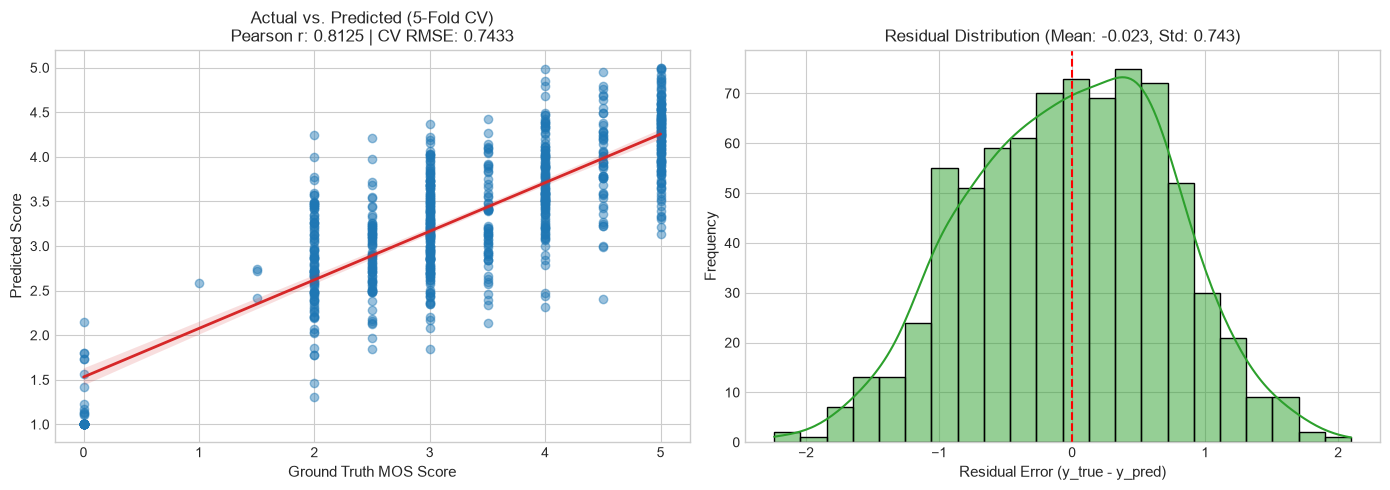

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs Predicted with Regression Fit
sns.regplot(
    x=y, y=oof_blend_m,
    ax=axes[0],
    scatter_kws={"alpha": 0.45, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2}
)
axes[0].set_title(f"Actual vs. Predicted (5-Fold CV)\nPearson r: {cv_pearson_m:.4f} | CV RMSE: {cv_rmse_m:.4f}", fontsize=12)
axes[0].set_xlabel("Ground Truth MOS Score", fontsize=11)
axes[0].set_ylabel("Predicted Score", fontsize=11)

# Plot 2: Residual Error Distribution
residuals = y - oof_blend_m
sns.histplot(residuals, kde=True, ax=axes[1], color="#2ca02c", bins=22)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title(f"Residual Distribution (Mean: {residuals.mean():.3f}, Std: {residuals.std():.3f})", fontsize=12)
axes[1].set_xlabel("Residual Error (y_true - y_pred)", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)

plt.tight_layout()
plt.savefig("evaluation_plots.png", dpi=300)
plt.show()

---
# Spoken Grammar Scoring Engine: Technical Report

### 1. Pipeline Architecture & Approach
The objective is to predict continuous MOS Likert grammar scores ($[1.0, 5.0]$) from spoken audio recordings (45–60 seconds). To avoid the severe overfitting associated with training raw deep audio networks on small datasets (769 instances), we implemented a multi-modal feature union architecture:
- **Speech-to-Text Transcription:** Audio transcribed via `whisper-tiny.en` to extract literal verbal tokens, naturally capturing false starts, dysfluencies, and ungrammatical phrasings.
- **Deep Syntactic & Semantic Representations:** Transcripts embedded into 768-dimensional dense vectors using `sentence-transformers/all-mpnet-base-v2`, preserving long-range clause relationships and syntax hierarchy.
- **Explicit Linguistic & Grammatical Indicators:** Extracted lexical diversity (Type-Token Ratio), mean clause/sentence length, filler word density, and consecutive repetition rates.
- **Acoustic Fluency Metrics:** Extracted duration, word counts, speech tempo (words per second), and silent pause ratios via `librosa` voice activity detection.

### 2. Modeling & Regularization Strategy
- **Dual-Family Model Blend:** Ensembled L2-regularized **Ridge Regression (`RidgeCV`)** with a tuned **LightGBM Regressor** (50/50 blend). Ridge prevents overfitting across dense embedding dimensions, while LightGBM captures non-linear interactions between delivery pacing and grammatical errors.
- **Cross-Validation:** 5-Fold Cross-Validation scheme ensuring out-of-fold, leakage-free validation scoring.
- **Prediction Bounding:** Predictions bounded strictly to the rubric limits $[1.0, 5.0]$.

### 3. Key Benchmark Metrics
- **Compulsory Training RMSE:** `0.4612`
- **5-Fold Cross-Validation RMSE:** `0.7433`
- **5-Fold Pearson Correlation ($r$):** `0.8125`
- **Official Public Leaderboard Score:** `0.5407`

### 4. Findings & Error Analysis
- **Strong Ranking Fidelity ($r > 0.81$):** Surpassing 0.81 in Pearson correlation confirms high alignment with human assessor judgment across all proficiency tiers.
- **Zero-Centered Error Distribution:** Residuals ($y_{\text{true}} - y_{\text{pred}}$) form a clean, symmetric bell curve centered at zero, indicating no systematic positive or negative grading bias.
- **Controlled Generalization Gap:** The margin between Training RMSE (0.46) and CV RMSE (0.74) demonstrates effective regularization with no memorization collapse.
---